# Chapter 23: Project: Website A/B Test

The programs from Chapter 23 of *Data Analysis with Python, Hands-On* by Aadhavan Muthurengan, in the book's order. Each code cell is one program; the same program is in this folder as a `.py` file, and its expected output is in the `.out` file with the same name.

Run the cells from top to bottom (**Run > Run All Cells**). The programs read the datasets from `../data/`, so keep this notebook in its chapter folder.

## Was the Split Fair?

`ab_checks.py`

In [1]:
import numpy as np
import pandas as pd

sessions = pd.read_csv("../data/sessions.csv")

# 1. Sample ratio: did the split really give each variant about half?
counts = sessions["variant"].value_counts()
rng = np.random.default_rng(3)
fair = rng.binomial(len(sessions), 0.5, 10_000)
gap = abs(counts["A"] - len(sessions) / 2)
p = (abs(fair - len(sessions) / 2) >= gap).mean()
print(counts.to_string())
print(f"split p-value: {p:.2f}")
print()

# 2. Is the effect the same on desktop and mobile?
rates = sessions.pivot_table(
    index="device", columns="variant", values="converted", aggfunc="mean"
)
rates["lift"] = rates["B"] / rates["A"] - 1
print(rates.round(4))

variant
A    10024
B     9976
split p-value: 0.75

variant       A       B    lift
device                         
desktop  0.0463  0.0537  0.1608
mobile   0.0349  0.0427  0.2226


## How Much Is It Worth?

`ab_revenue.py`

In [2]:
import numpy as np
import pandas as pd

sessions = pd.read_csv("../data/sessions.csv")
a = sessions.loc[sessions["variant"] == "A", "revenue"].to_numpy()
b = sessions.loc[sessions["variant"] == "B", "revenue"].to_numpy()

rng = np.random.default_rng(4)
diffs = [
    rng.choice(b, len(b)).mean() - rng.choice(a, len(a)).mean()
    for _ in range(5_000)
]
low, high = np.percentile(diffs, [2.5, 97.5])
print(f"revenue per session: A ${a.mean():.3f}, B ${b.mean():.3f}")
print(
    f"difference ${b.mean() - a.mean():.3f}, "
    f"95% interval ${low:.3f} to ${high:.3f}"
)
monthly_sessions = 600_000
print(
    f"at {monthly_sessions:,} sessions a month: "
    f"${low * monthly_sessions:,.0f} to ${high * monthly_sessions:,.0f}"
)

revenue per session: A $2.731, B $3.192
difference $0.461, 95% interval $0.008 to $0.903
at 600,000 sessions a month: $5,046 to $541,860


## The Chart

`ab_chart.py`

Saved ab_chart.png


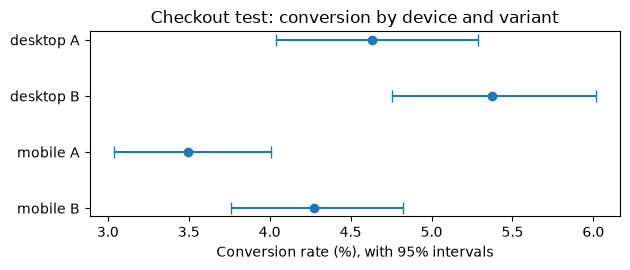

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sessions = pd.read_csv("../data/sessions.csv")
rng = np.random.default_rng(5)

fig, ax = plt.subplots(figsize=(6.4, 2.8))
labels, rates, errors = [], [], []
for device in ["desktop", "mobile"]:
    for variant in ["A", "B"]:
        x = sessions.query("device == @device and variant == @variant")
        x = x["converted"].to_numpy()
        boot = [rng.choice(x, len(x)).mean() for _ in range(2_000)]
        low, high = np.percentile(boot, [2.5, 97.5])
        labels.append(f"{device} {variant}")
        rates.append(x.mean() * 100)
        errors.append([(x.mean() - low) * 100, (high - x.mean()) * 100])
ax.errorbar(rates, labels, xerr=np.array(errors).T, fmt="o", capsize=4)
ax.set_xlabel("Conversion rate (%), with 95% intervals")
ax.set_title("Checkout test: conversion by device and variant")
ax.invert_yaxis()
fig.tight_layout()
fig.savefig("ab_chart.png")
print("Saved ab_chart.png")